# Rent 10 · Model: which problems should a renter expect?
**Know Before You Rent · Team BUTA**

**Q5:** for a given building, how likely is each problem type next year, and why?

- **One classifier per problem type:** heat/hot water, pests, leaks/mold, plumbing, paint/plaster, doors/windows, safety.
- **Train** on the 2024 table (history 2022–23). **Test** on 2025 (history 2023–24), a year the model never saw.
- **Models compared:**
  1. **Baseline:** "it will happen again if it happened before".
  2. **Logistic regression:** simple, and explainable.
  3. **Gradient-boosted trees:** flexible, and handles missing values.
- **Metrics:**
  - **AUC:** how well the model ranks risky buildings above safe ones. 0.5 is random, 1 is perfect.
  - **Average precision:** how well it finds the buildings that actually get the problem. Compare it to the base rate.
  - **Brier score:** how accurate the probabilities themselves are. Lower is better.

Code: `src/model_housing.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import features_housing as F, model_housing as M
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.3f}".format)
train = pd.read_parquet(str(F.FEATURES_FILE).format(year=2024))
test = pd.read_parquet(str(F.FEATURES_FILE).format(year=2025))
cols = F.feature_columns(train)
print(f"train {len(train):,} buildings | test {len(test):,} | {len(cols)} features")
{k: len(v) for k, v in M.feature_groups(cols).items()}

train 172,546 buildings | test 172,546 | 47 features


{'building': 6, 'history': 24, 'landlord': 9, 'neighborhood': 8}

## 1. Baseline vs logistic regression vs gradient boosting

In [2]:
results, fitted = M.evaluate(train, test)
pivot = results.pivot(index="problem", columns="model", values="auc")[["baseline: had it before", "logit", "gbm"]]
display(pivot.style.format("{:.3f}").background_gradient(cmap="Purples", axis=1).set_caption("Test AUC (2025)"))
results.pivot(index="problem", columns="model", values="avg_precision").join(
    results.drop_duplicates("problem").set_index("problem")["base_rate"])

model,baseline: had it before,logit,gbm
problem,,,
doors/windows,0.800,0.903,0.924
heat/hot water,0.831,0.890,0.913
leaks/mold,0.820,0.899,0.918
paint/plaster,0.820,0.908,0.928
pests,0.799,0.890,0.912
plumbing,0.801,0.900,0.919
safety,0.695,0.865,0.891


,baseline: had it before,gbm,logit,base_rate
problem,,,,
doors/windows,0.475,0.631,0.601,0.080
heat/hot water,0.649,0.770,0.733,0.168
leaks/mold,0.548,0.681,0.651,0.104
paint/plaster,0.527,0.670,0.639,0.085
pests,0.482,0.629,0.598,0.089
plumbing,0.504,0.668,0.637,0.095
safety,0.195,0.359,0.333,0.038


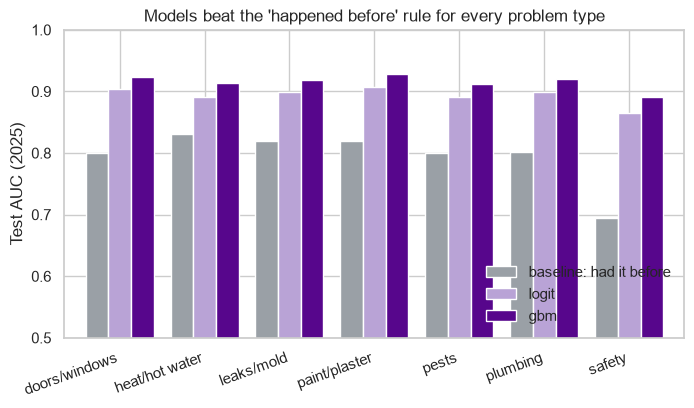

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
pivot.plot(kind="bar", ax=ax, color=[MUTED, "#b9a3d6", ACCENT], width=0.8)
ax.set(ylim=(0.5, 1), ylabel="Test AUC (2025)", xlabel="", title="Models beat the 'happened before' rule for every problem type")
ax.legend(frameon=False, loc="lower right"); plt.xticks(rotation=20, ha="right")
save(fig, "rent10a_model_comparison")

## 2. Which information matters? Feature-group ablation
Start with building traits only, then add own history, then the landlord, then the 100 m neighborhood. Each step is retrained and scored on 2025.

In [4]:
abl = M.ablation(train, test)
abl_auc = abl.pivot(index="problem", columns="features", values="auc")
abl_auc = abl_auc[sorted(abl_auc.columns, key=len)]
display(abl_auc.style.format("{:.3f}").background_gradient(cmap="Purples", axis=1))
gain = abl_auc.diff(axis=1).iloc[:, 1:]
gain.columns = ["+ history", "+ landlord", "+ neighborhood"]
gain.style.format("{:+.3f}").set_caption("AUC gained by each added group")

features,building,building + history,building + history + landlord,building + history + landlord + neighborhood
problem,,,,
doors/windows,0.861,0.922,0.923,0.924
heat/hot water,0.859,0.909,0.911,0.913
leaks/mold,0.859,0.915,0.918,0.918
paint/plaster,0.870,0.925,0.927,0.928
pests,0.850,0.908,0.910,0.912
plumbing,0.862,0.917,0.919,0.919
safety,0.829,0.890,0.891,0.891


,+ history,+ landlord,+ neighborhood
problem,,,
doors/windows,+0.061,+0.002,+0.001
heat/hot water,+0.050,+0.002,+0.002
leaks/mold,+0.055,+0.003,+0.001
paint/plaster,+0.055,+0.002,+0.001
pests,+0.058,+0.002,+0.001
plumbing,+0.055,+0.002,+0.001
safety,+0.061,+0.001,+0.000


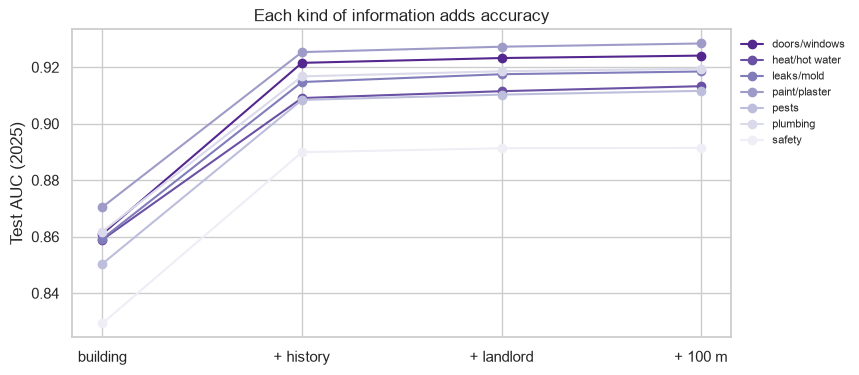

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for (problem, row), color in zip(abl_auc.iterrows(), sns.color_palette("Purples_r", len(abl_auc))):
    ax.plot(range(len(row)), row.values, "-o", color=color, label=problem)
ax.set_xticks(range(abl_auc.shape[1]), ["building", "+ history", "+ landlord", "+ 100 m"])
ax.set(ylabel="Test AUC (2025)", title="Each kind of information adds accuracy")
ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
save(fig, "rent10b_ablation")

## 3. Permutation importance by group (gradient boosting, all features)
How much test AUC drops when one group's columns are shuffled.

In [6]:
imp_rows, per_feature = [], {}
for problem in F.TARGET_TYPES:
    g, pf = M.group_importance(fitted[(problem, "gbm")], test, problem)
    imp_rows.append(g); per_feature[problem] = pf
imp = pd.DataFrame(imp_rows)
display(imp.style.format("{:.3f}").background_gradient(cmap="Purples", axis=1))
pd.DataFrame(per_feature).mean(axis=1).sort_values(ascending=False).head(15).rename("mean AUC drop").to_frame()

,building,history,landlord,neighborhood
heat/hot water,0.026,0.041,0.002,0.003
pests,0.015,0.089,0.002,0.003
leaks/mold,0.014,0.054,0.002,0.003
plumbing,0.015,0.090,0.002,0.004
paint/plaster,0.017,0.068,0.001,0.004
doors/windows,0.013,0.074,0.002,0.004
safety,0.012,0.093,0.003,0.002


,mean AUC drop
c_total,0.068
unitsres,0.011
is_registered,0.003
nb100_buildings,0.001
building_age,0.001
v_class_B,0.001
nb100_pests,0.001
c_heat_hot_water,0.001
ll_rate_leaks_mold,0.001
v_class_C,0.001


## 4. Are the probabilities honest? (calibration)

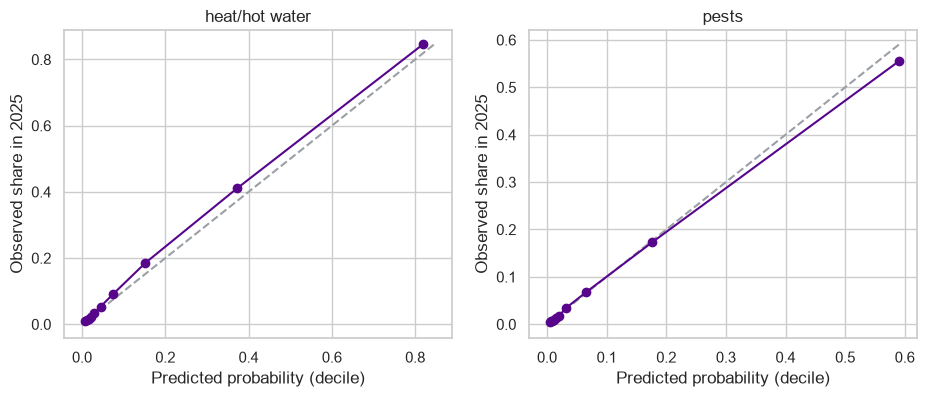

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, problem in zip(axes, ["heat/hot water", "pests"]):
    y = test[f"y_{F.slug(problem)}"]
    p = fitted[(problem, "gbm")].predict_proba(M.to_matrix(test, cols))[:, 1]
    bins = pd.qcut(p, 10, duplicates="drop")
    cal = pd.DataFrame({"pred": p, "obs": y}).groupby(bins, observed=True).mean()
    ax.plot([0, cal.max().max()], [0, cal.max().max()], "--", color=MUTED)
    ax.plot(cal["pred"], cal["obs"], "-o", color=ACCENT)
    ax.set(title=problem, xlabel="Predicted probability (decile)", ylabel="Observed share in 2025")
save(fig, "rent10c_calibration")

## 5. From probability to a renter report

In [8]:
base = {p: test[f"y_{F.slug(p)}"].mean() for p in F.TARGET_TYPES}
X_te = M.to_matrix(test, cols)
probs = pd.DataFrame({p: fitted[(p, "gbm")].predict_proba(X_te)[:, 1] for p in F.TARGET_TYPES}, index=test.index)
levels = pd.DataFrame({p: M.risk_level(probs[p], base[p]) for p in F.TARGET_TYPES}, index=test.index)

# How well do the levels separate risk? Observed 2025 rate per level
check = {p: test.groupby(levels[p])[f"y_{F.slug(p)}"].mean() for p in F.TARGET_TYPES}
pd.DataFrame(check).T[["Low", "Medium", "High"]].mul(100).round(1).rename_axis("observed % with problem in 2025")

,Low,Medium,High
observed % with problem in 2025,,,
heat/hot water,3.900,24.400,71.600
pests,1.700,11.300,45.400
leaks/mold,1.800,12.400,50.100
plumbing,1.700,12.500,49.800
paint/plaster,1.300,9.900,46.300
doors/windows,1.300,9.800,43.400
safety,0.800,4.700,21.400


In [9]:
def renter_report(i):
    row = test.loc[[i]]
    print(f"BBL {row.bbl.iat[0]} · {row.borough.iat[0]} {row.zipcode.iat[0]} · built {row.yearbuilt.iat[0]:.0f} · "
          f"{row.unitsres.iat[0]:.0f} apartments · landlord portfolio: {row.portfolio_buildings.iat[0]:.0f} buildings")
    for p in sorted(F.TARGET_TYPES, key=lambda p: -probs.at[i, p]):
        reasons = M.explain(fitted[(p, "logit")], row, cols, p)
        print(f"  {levels.at[i, p]:6s} {p:15s} {probs.at[i, p]:.0%}   " + ("; ".join(reasons) if levels.at[i, p] != "Low" else ""))

# Three example buildings: high, typical and low overall risk
overall = probs.mean(axis=1)
for i in [overall.idxmax(), overall.sub(overall.median()).abs().idxmin(), overall.idxmin()]:
    renter_report(i); print()

BBL 2045060001 · BRONX 10467 · built 1927 · 716 apartments · landlord portfolio: 226 buildings
  High   paint/plaster   99%   this building had 544 total complaint(s) in the last 2 years; this building had 82 paint plaster complaint(s) in the last 2 years; this building had 110 leaks mold complaint(s) in the last 2 years
  High   leaks/mold      99%   this building had 544 total complaint(s) in the last 2 years; this building had 110 leaks mold complaint(s) in the last 2 years; inspectors issued 221 doors windows violation(s) in the last 2 years
  High   heat/hot water  99%   this building had 544 total complaint(s) in the last 2 years; this building had 234 heat hot water complaint(s) in the last 2 years; inspectors issued 221 doors windows violation(s) in the last 2 years
  High   doors/windows   99%   this building had 544 total complaint(s) in the last 2 years; this building had 95 doors windows complaint(s) in the last 2 years; inspectors issued 723 class B violation(s) in the las

## 6. Save the models

In [10]:
M.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump({"features": cols, "base_rates": base, "models": fitted}, M.MODELS_DIR / "kbyr_models.joblib")
results.to_csv(ROOT / "reports" / "model_results.csv", index=False)
print("Saved models →", (M.MODELS_DIR / "kbyr_models.joblib").relative_to(ROOT))

Saved models → models/kbyr_models.joblib


## Summary (fill in from the outputs above)
- **Q5:** the models predict next year's problems with AUC between ___ and ___, beating the "happened before" baseline for every type.
- **Q1:** own history is the strongest single group. Problems repeat.
- **Q2:** the landlord's other buildings add ___ AUC on top of history. **The landlord matters.**
- **Q4:** the 100 m neighborhood adds a little more: ___.
- **Risk levels:** a "High" building is ___× more likely than a "Low" one to get heat complaints.

→ Next: Flask demo, an address in and this report out.